# Лабораторная работа №6. Использование внешних библиотек

Монгуш Темир Мергенович · ИУ5-35Б · вариант 11

**Движение №8:** спираль из центра — вниз, вправо, вверх, влево. При достижении границы — новый проход из центра другим цветом. Цвета: белый и жёлтый. Клавиши: `j` — выход, `l` — скорость.

[Условие и схема](https://github.com/junaart/System_programming/blob/master/Lab_6/Lab_6.ipynb) · [Лекция о ncurses](https://github.com/junaart/System_programming/blob/master/Lection_9/Lection_9.ipynb)

В Colab выполни ячейки сверху вниз. Проверка запускает программу в псевдотерминале Linux и показывает сохранённые кадры. Для ручного управления запусти `./spiral` в обычном Linux-терминале.

## Вариант

In [1]:
import random as rd

Variant = 11
rd.seed(Variant)
colors = ['COLOR_BLACK', 'COLOR_RED', 'COLOR_GREEN', 'COLOR_YELLOW', 'COLOR_BLUE', 'COLOR_MAGENTA', 'COLOR_CYAN', 'COLOR_WHITE']
buttons = ['q','w','e','r','t','y','u','i','o','p','a','s','d','f','g','h','j','k','l','z','x','c','v','b','n','m']
movement = rd.sample(range(1, 9), 1)
fill = rd.sample(colors, 2)
keys = rd.sample(buttons, 2)
print('Алгоритм:', movement)
print('Цвета:', fill)
print('Выход, скорость:', keys)
assert (movement, fill, keys) == ([8], ['COLOR_WHITE', 'COLOR_YELLOW'], ['j', 'l'])

Алгоритм: [8]
Цвета: ['COLOR_WHITE', 'COLOR_YELLOW']
Выход, скорость: ['j', 'l']


## Подготовка

In [2]:
%%bash
set -e
packages=(fasm gcc binutils file libncurses-dev python3-pyte python3-pil fonts-dejavu-core)
if ! dpkg -s "${packages[@]}" >/dev/null 2>&1; then
    SUDO=()
    if [ "$(id -u)" -ne 0 ]; then SUDO=(sudo); fi
    "${SUDO[@]}" apt-get update -qq
    "${SUDO[@]}" env DEBIAN_FRONTEND=noninteractive apt-get install -y -qq "${packages[@]}"
fi
mkdir -p Lab_6
uname -sm

Linux x86_64


## Исходный код и сборка

Длины отрезков: 1, 1, 2, 2, 3, 3, … . Белый и жёлтый фон задаются через [`init_pair`](https://invisible-island.net/ncurses/man/curs_color.3x.html). Ожидание клавиши одновременно задаёт задержку следующего шага.

In [3]:
%%writefile Lab_6/spiral.asm
; ЛР 6, вариант 11. FASM, Linux x86-64, ncurses.
format ELF64
public main
extrn initscr
extrn endwin
extrn cbreak
extrn noecho
extrn start_color
extrn init_pair
extrn getmaxx
extrn getmaxy
extrn clear
extrn move
extrn clrtoeol
extrn printw
extrn timeout
extrn getch
extrn mvaddch
extrn refresh
extrn puts

section '.data' writable
    step_x dd 0, 1, 0, -1
    step_y dd 1, 0, -1, 0      ; вниз, вправо, вверх, влево
    delays dd 90, 30, 5
    status db 'j: exit | l: speed | %d ms | pass %d', 0
    error_msg db 'Need a color terminal of at least 40 columns and 5 rows.', 0
    pair dd 1
    pass_number dd 1
    speed dd 0

section '.bss' writable
    window rq 1
    width rd 1
    height rd 1
    x rd 1
    y rd 1
    direction rd 1
    side rd 1                  ; длина текущего отрезка
    left_steps rd 1

section '.text' executable
main:
    push rbp                   ; выравниваем стек перед вызовами C
    call initscr
    mov [window], rax
    call cbreak
    call noecho
    call start_color
    test eax, eax
    js .error

    mov edi, 1
    xor esi, esi               ; COLOR_BLACK — цвет текста
    mov edx, 7                 ; COLOR_WHITE — фон первой пары
    call init_pair
    test eax, eax
    js .error
    mov edi, 2
    xor esi, esi
    mov edx, 3                 ; COLOR_YELLOW — фон второй пары
    call init_pair
    test eax, eax
    js .error

.resize:
    mov rdi, [window]
    call getmaxx
    mov [width], eax
    cmp eax, 40
    jl .error
    mov rdi, [window]
    call getmaxy
    mov [height], eax
    cmp eax, 5
    jl .error
    call clear

.restart:
    mov eax, [width]
    shr eax, 1
    mov [x], eax
    mov eax, [height]           ; строка 0 отведена под управление
    shr eax, 1
    mov [y], eax
    mov [direction], 0
    mov [side], 1
    mov [left_steps], 1

.show_status:
    xor edi, edi
    xor esi, esi
    call move
    call clrtoeol
    mov eax, [speed]
    mov esi, [delays+rax*4]
    mov edx, [pass_number]
    mov rdi, status
    xor eax, eax               ; у printw нет векторных аргументов
    call printw
    mov eax, [speed]
    mov edi, [delays+rax*4]
    call timeout

.frame:
    mov edi, [y]
    mov esi, [x]
    mov edx, [pair]
    shl edx, 8                 ; COLOR_PAIR(pair) для ncurses
    or edx, ' '                ; рисуем пробел с цветным фоном
    call mvaddch
    mov edi, [y]
    mov esi, [x]
    call move                 ; курсор остаётся на цветной клетке
    call refresh
    call getch                ; клавиша или ожидание до следующего кадра
    cmp eax, 'j'
    je .exit
    cmp eax, 'l'
    je .change_speed
    cmp eax, 410              ; KEY_RESIZE
    je .resize

    ; После показа граничной клетки возвращаемся в центр.
    mov eax, [x]
    test eax, eax
    jz .next_pass
    inc eax
    cmp eax, [width]
    je .next_pass
    mov eax, [y]
    cmp eax, 1
    je .next_pass
    inc eax
    cmp eax, [height]
    je .next_pass

    mov eax, [direction]
    mov edx, [step_x+rax*4]
    add [x], edx
    mov edx, [step_y+rax*4]
    add [y], edx
    dec [left_steps]
    jnz .frame
    inc eax
    and eax, 3                ; после последнего направления снова вниз
    mov [direction], eax
    test eax, 1
    jnz .keep_side
    inc [side]                ; после двух поворотов: 1,1,2,2,3,3,...
.keep_side:
    mov eax, [side]
    mov [left_steps], eax
    jmp .frame

.change_speed:
    inc [speed]
    cmp [speed], 3
    jb .show_status
    mov [speed], 0
    jmp .show_status

.next_pass:
    xor [pair], 3             ; 1 -> 2, 2 -> 1
    inc [pass_number]
    jmp .restart

.exit:
    call endwin
    xor eax, eax
    pop rbp
    ret

.error:
    call endwin
    mov rdi, error_msg
    call puts
    mov eax, 1
    pop rbp
    ret

Writing Lab_6/spiral.asm


In [4]:
%%bash
set -e
cd Lab_6
fasm spiral.asm spiral.o
gcc -no-pie -Wl,-z,noexecstack spiral.o -lncurses -o spiral
file spiral
readelf -d spiral | grep NEEDED

flat assembler  version 1.73.32  (16384 kilobytes memory)
4 passes, 3464 bytes.
spiral: ELF 64-bit LSB executable, x86-64, version 1 (SYSV), dynamically linked, interpreter /lib64/ld-linux-x86-64.so.2, BuildID[sha1]=858488605c2b21ec9af10198c2c96d5cd7f3937a, for GNU/Linux 3.2.0, not stripped
 0x0000000000000001 (NEEDED)             Shared library: [libncurses.so.6]
 0x0000000000000001 (NEEDED)             Shared library: [libtinfo.so.6]
 0x0000000000000001 (NEEDED)             Shared library: [libc.so.6]


## Проверка: движение, смена цвета, клавиши

In [5]:
%%writefile Lab_6/check_spiral.py
"""Проверка реального вывода ncurses в псевдотерминале Linux."""

import fcntl
import os
import pty
import select
import struct
import subprocess
import termios
import time

import pyte
from pyte.graphics import BG_ANSI
from PIL import Image, ImageDraw, ImageFont

ROWS, COLS = 9, 52
WHITE, YELLOW = BG_ANSI[47], BG_ANSI[43]
COLORS = {WHITE: '#efefef', YELLOW: '#f2d253', 'black': '#191919'}


def save_frame(screen, name):
    font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSansMono.ttf', 17)
    w, h, pad = 11, 24, 14
    image = Image.new('RGB', (COLS*w+2*pad, ROWS*h+2*pad), '#191919')
    draw = ImageDraw.Draw(image)
    for row in range(ROWS):
        for col in range(COLS):
            cell = screen.buffer[row][col]
            x, y = pad+col*w, pad+row*h
            draw.rectangle((x, y, x+w-1, y+h-1), fill=COLORS.get(cell.bg, '#191919'))
            if cell.data != ' ':
                draw.text((x, y+1), cell.data, font=font, fill=COLORS.get(cell.fg, '#efefef'))
    x, y = pad+screen.cursor.x*w, pad+screen.cursor.y*h
    draw.rectangle((x, y, x+w-1, y+h-1), outline='#888888')
    image.save(name)


def main():
    master, slave = pty.openpty()
    fcntl.ioctl(slave, termios.TIOCSWINSZ, struct.pack('HHHH', ROWS, COLS, 0, 0))
    original_mode = termios.tcgetattr(slave)
    env = dict(os.environ, TERM='xterm-256color', LC_ALL='C')
    for key in ('LINES', 'COLUMNS', 'NCURSES_NO_UTF8_ACS'):
        env.pop(key, None)
    process = subprocess.Popen(['./spiral'], stdin=slave, stdout=slave, stderr=slave, env=env)
    screen = pyte.Screen(COLS, ROWS)
    stream = pyte.ByteStream(screen)

    def cells(color):
        return {(r, c) for r in range(1, ROWS) for c in range(COLS)
                if screen.buffer[r][c].bg == color}

    def wait_for(predicate):
        end = time.monotonic() + 8
        while time.monotonic() < end:
            if predicate():
                return
            if select.select([master], [], [], 0.05)[0]:
                stream.feed(os.read(master, 65536))
            if process.poll() is not None:
                break
        raise AssertionError(f'Expected frame not found: {screen.display!r}')

    try:
        # Первые восемь клеток по схеме варианта, включая центральную.
        first = {(4, 26), (5, 26), (5, 27), (4, 27), (3, 27), (3, 26), (3, 25), (4, 25)}
        wait_for(lambda: cells(WHITE) == first)
        assert (screen.cursor.y, screen.cursor.x) == (4, 25)
        print('Движение №8: первые восемь клеток и положение курсора — OK')
        assert '90 ms | pass 1' in screen.display[0]
        os.write(master, b'l')
        wait_for(lambda: '30 ms | pass 1' in screen.display[0] and len(cells(WHITE)) >= 25)
        save_frame(screen, 'white.png')
        os.write(master, b'l')
        wait_for(lambda: '5 ms | pass 2' in screen.display[0] and len(cells(YELLOW)) >= 17)
        assert (4, 26) in cells(YELLOW)
        assert any(r in (1, ROWS-1) or c in (0, COLS-1) for r, c in cells(WHITE))
        save_frame(screen, 'yellow.png')
        print('Граница достигнута: следующий проход начался в центре жёлтым — OK')
        os.write(master, b'l')
        wait_for(lambda: '90 ms | pass' in screen.display[0])
        print('l: задержка меняется 90 → 30 → 5 → 90 мс — OK')
        os.write(master, b'j')
        assert process.wait(timeout=3) == 0
        assert termios.tcgetattr(slave) == original_mode
        print('j: выход с кодом 0, настройки терминала восстановлены — OK')
    finally:
        if process.poll() is None:
            process.kill()
            process.wait()
        os.close(slave)
        os.close(master)


if __name__ == '__main__':
    main()

Writing Lab_6/check_spiral.py


In [6]:
%%bash
set -e
cd Lab_6
/usr/bin/python3 check_spiral.py

Движение №8: первые восемь клеток и положение курсора — OK
Граница достигнута: следующий проход начался в центре жёлтым — OK
l: задержка меняется 90 → 30 → 5 → 90 мс — OK
j: выход с кодом 0, настройки терминала восстановлены — OK


Первый кадр — белый проход. Второй — жёлтый проход после достижения границы.

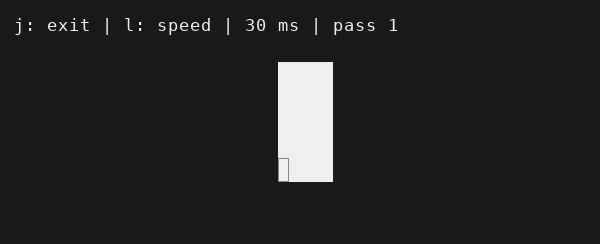

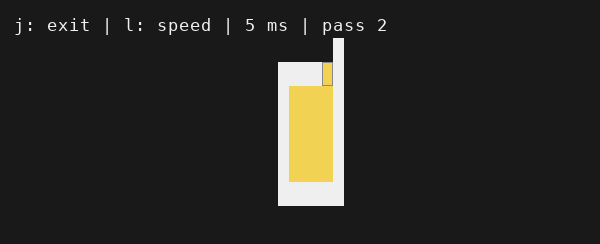

In [7]:
from IPython.display import Image, display

for name in ('white.png', 'yellow.png'):
    display(Image(filename=f'Lab_6/{name}'))